#**NLP : Classification des critiques des films**

***📊 Comparaison de modèles pour la classification de texte***

Ce notebook compare les performances de deux modèles classiques de Machine Learning — **la Régression Logistique (LR)** et le **Support Vector Machine (SVM)** — sur une tâche de classification de texte, en utilisant différentes représentations vectorielles (TF-IDF, Word2Vec, BERT).

L'objectif est d'identifier quel couple **modèle + représentation** offre les meilleurs résultats en termes de précision, tout en évaluant la stabilité et la facilité d'optimisation des approches.

In [ ]:
!pip install wordcloud


In [ ]:
import os
import pandas as pd

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# --- CRITICAL: BASE PATH DEFINITION ---
# This is the path to the 'Data' folder containing 'train' and 'test'.
BASE_DIR = '/content/drive/MyDrive/Colab Notebooks/Data'

# --- YOUR REQUESTED PATH VARIABLES ---

# Training Paths
train_pos_path = os.path.join(BASE_DIR, 'train', 'pos')
train_neg_path = os.path.join(BASE_DIR, 'train', 'neg')

# Testing Paths
test_pos_path = os.path.join(BASE_DIR, 'test', 'pos')
test_neg_path = os.path.join(BASE_DIR, 'test', 'neg')


# --- VERIFICATION ---
print("✅ Path variables defined successfully:")
print(f"train_pos_path: {train_pos_path}")
print(f"train_neg_path: {train_neg_path}")
print(f"test_pos_path: {test_pos_path}")
print(f"test_neg_path: {test_neg_path}")

# Run a quick check to ensure the directories actually exist
if os.path.isdir(train_pos_path):
    print("\nDirectory check successful. Ready to load data.")
else:
    print("\n❌ ERROR: Directory not found. Please confirm the BASE_DIR is correct.")

In [ ]:
def load_reviews_from_folder(folder, sentiment):
    reviews = []
    for filename in os.listdir(folder):
        if filename.endswith(".txt"):
            with open(os.path.join(folder, filename), "r", encoding="utf-8") as f:
                reviews.append(f.read())
    return pd.DataFrame({"review": reviews, "sentiment": sentiment})

In [ ]:
df_train_pos = load_reviews_from_folder(train_pos_path, "positive")
df_train_neg = load_reviews_from_folder(train_neg_path, "negative")

df_train = pd.concat([df_train_pos, df_train_neg]).reset_index(drop=True)

In [ ]:
df_test_pos = load_reviews_from_folder(test_pos_path, "positive")
df_test_neg = load_reviews_from_folder(test_neg_path, "negative")

df_test = pd.concat([df_test_pos, df_test_neg]).reset_index(drop=True)

In [ ]:
print("Taille train :", len(df_train))
print("Taille test :", len(df_test))

df_train.head()

Taille train : 25000
Taille test : 25000


,review,sentiment
0,I was lucky enough to see Zero Day last night....,positive
1,There I was sitting alone in my flat on a Satu...,positive
2,I'd love to give Kolchak a higher rating but t...,positive
3,I just came back from the Montreal premiere of...,positive
4,"I bought this movie a few days ago, and though...",positive


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="sentiment", data=df_train)
plt.title("Distribution des sentiments - Train")
plt.show()

In [ ]:
df_train["review_length"] = df_train["review"].apply(lambda x: len(x.split()))
df_train["review_length"].describe()

# Visualisation
plt.hist(df_train["review_length"], bins=50)
plt.title("Distribution de la longueur des reviews")
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre de reviews")
plt.show()

In [ ]:
from wordcloud import WordCloud

# Positives
pos_text = " ".join(df_train[df_train["sentiment"]=="positive"]["review"])
wordcloud_pos = WordCloud(width=800, height=400, background_color='white').generate(pos_text)
plt.figure(figsize=(10,5))
plt.imshow(wordcloud_pos, interpolation='bilinear')
plt.axis("off")
plt.title("WordCloud - Positive Reviews")
plt.show()

# Negatives
neg_text = " ".join(df_train[df_train["sentiment"]=="negative"]["review"])
wordcloud_neg = WordCloud(width=800, height=400, background_color='white').generate(neg_text)
plt.figure(figsize=(10,5))
plt.imshow(wordcloud_neg, interpolation='bilinear')
plt.axis("off")
plt.title("WordCloud - Negative Reviews")
plt.show()

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("wordnet")

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z]", " ", text)  # Retirer caractères spéciaux
    words = text.split()
    words = [word for word in words if word not in stop_words]  # Supprimer stopwords
    words = [lemmatizer.lemmatize(word) for word in words]      # Lemmatization
    return " ".join(words)

df_train["cleaned_review"] = df_train["review"].apply(clean_text)
df_test["cleaned_review"] = df_test["review"].apply(clean_text)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


# TF-IDF : Term Frequency-Inverse Document Frequency
TF-IDF pèse la fréquence des mots par leur importance à travers les documents

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train = tfidf.fit_transform(df_train["cleaned_review"])
X_test = tfidf.transform(df_test["cleaned_review"])

y_train = df_train["sentiment"]
y_test = df_test["sentiment"]

#BERT embedings avec fine-tuné SST-2

In [ ]:
!pip install transformers

from transformers import AutoTokenizer, AutoModel
import torch
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name).to(device)
model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSdpaAttention(
          (dropout): Dropout(p=0.1, inplace=False)
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): L

In [ ]:
def get_distilbert_embeddings(text_list, batch_size=32):
    all_embeddings = []

    for i in range(0, len(text_list), batch_size):
        batch = text_list[i:i+batch_size]

        encoded = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = model(**encoded)

        # DistilBERT n'a pas CLS explicitement → c’est le token 0
        cls_vectors = outputs.last_hidden_state[:, 0, :].cpu().numpy()
        all_embeddings.append(cls_vectors)

    return np.vstack(all_embeddings)

In [ ]:
X_train_distil = get_distilbert_embeddings(df_train["cleaned_review"].tolist())
X_test_distil = get_distilbert_embeddings(df_test["cleaned_review"].tolist())

y_train = df_train["sentiment"]
y_test = df_test["sentiment"]


# Word2Vec

In [ ]:
!pip install gensim
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 43.8 MB/s eta 0:00:00


In [ ]:
# Convert each review into list of words
sentences = df_train["cleaned_review"].apply(simple_preprocess).tolist()
sentences[:3]  # preview

[['lucky',
  'enough',
  'see',
  'zero',
  'day',
  'last',
  'night',
  'amazing',
  'movie',
  'disturbing',
  'one',
  'br',
  'br',
  'way',
  'zero',
  'day',
  'comparable',
  'blair',
  'witch',
  'project',
  'shot',
  'completley',
  'handheld',
  'camcorder',
  'kid',
  'average',
  'kid',
  'andre',
  'calvin',
  'start',
  'campaign',
  'high',
  'school',
  'entitled',
  'army',
  'br',
  'br',
  'whole',
  'story',
  'told',
  'video',
  'diary',
  'form',
  'kid',
  'show',
  'relationship',
  'parent',
  'amongst',
  'people',
  'showing',
  'normal',
  'kid',
  'like',
  'people',
  'know',
  'bumped',
  'find',
  'army',
  'last',
  'mission',
  'entitles',
  'zero',
  'day',
  'plan',
  'shoot',
  'high',
  'school',
  'br',
  'br',
  'see',
  'get',
  'access',
  'gun',
  'plan',
  'everything',
  'stress',
  'medium',
  'affected',
  'reason',
  'like',
  'said',
  'told',
  'video',
  'diary',
  'form',
  'store',
  'tape',
  'safety',
  'deposit',
  'box',
  'se

In [ ]:
model_w2v = Word2Vec(
    sentences,
    vector_size=100,  # embedding size
    window=5,         # context window
    min_count=2,      # ignore rare words
    sg=1,             # Skip-gram (better for sentiment)
    workers=4,
    epochs=10
)

print("Vocabulary size:", len(model_w2v.wv.key_to_index))

Vocabulary size: 40905


In [ ]:
def get_sentence_vector(sentence, model):
    words = simple_preprocess(sentence)
    valid_words = [w for w in words if w in model.wv.key_to_index]

    if not valid_words:
        return np.zeros(model.vector_size)

    return np.mean([model.wv[w] for w in valid_words], axis=0)

In [ ]:
X_train_w2v = np.vstack([
    get_sentence_vector(text, model_w2v)
    for text in df_train["cleaned_review"]
])

X_test_w2v = np.vstack([
    get_sentence_vector(text, model_w2v)
    for text in df_test["cleaned_review"]
])

y_train = df_train["sentiment"]
y_test = df_test["sentiment"]

X_train_w2v.shape, X_test_w2v.shape

((25000, 100), (25000, 100))

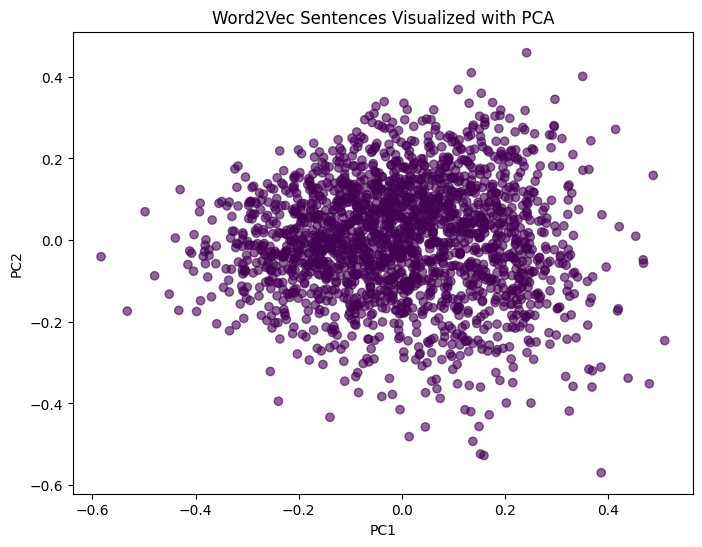

In [ ]:
# PCA Visualization (2D)
subset = 2000  # to avoid lag
X_sub = X_train_w2v[:subset]
y_sub = y_train[:subset]

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_sub)

plt.figure(figsize=(8,6))
plt.scatter(
    X_pca[:,0], X_pca[:,1],
    c=(y_sub == "positive"), alpha=0.6
)
plt.title("Word2Vec Sentences Visualized with PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

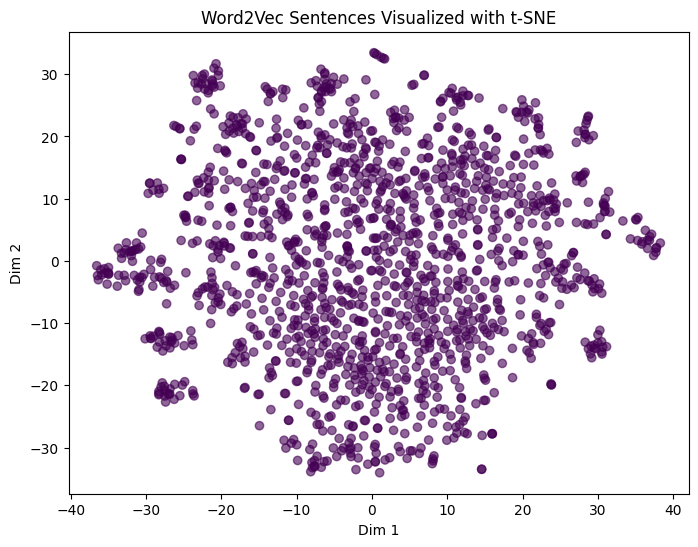

In [ ]:
# t-SNE Visualization (2D)
subset = 1500
X_sub = X_train_w2v[:subset]
y_sub = y_train[:subset]

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_sub)

plt.figure(figsize=(8,6))
plt.scatter(
    X_tsne[:,0], X_tsne[:,1],
    c=(y_sub == "positive"), alpha=0.6
)
plt.title("Word2Vec Sentences Visualized with t-SNE")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.show()

# Régression Logistique + TF-IDF

In [ ]:
# Importer la Régression Logistique
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [ ]:
# Diviser X_train en : vrai train + validation (80% / 20%)
X_train_tfidf, X_val_tfidf, y_train_tfidf, y_val_tfidf = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

In [ ]:
# Définir le modèle de Régression Logistique
log_reg_tfidf = LogisticRegression(
    max_iter=200,
    C=1.0,
    solver="liblinear"
)

# Entraîner sur le set train
log_reg_tfidf.fit(X_train_tfidf, y_train_tfidf)

LogisticRegression(max_iter=200, solver='liblinear')

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Prédictions validation
val_pred = log_reg_tfidf.predict(X_val_tfidf)

# Accuracy
val_accuracy = accuracy_score(y_val_tfidf, val_pred)
print("Accuracy Validation (TF-IDF + Logistic Regression) :", val_accuracy)

# Rapport de classification
print(classification_report(y_val_tfidf, val_pred))

Accuracy Validation (TF-IDF + Logistic Regression) : 0.8848
              precision    recall  f1-score   support

    negative       0.89      0.87      0.88      2500
    positive       0.88      0.90      0.89      2500

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000



In [ ]:
# Prédiction sur le test set final
test_pred = log_reg_tfidf.predict(X_test)

# Accuracy test
test_accuracy = accuracy_score(y_test, test_pred)
print("Accuracy Test Final :", test_accuracy)

# Rapport final
print(classification_report(y_test, test_pred))

Accuracy Test Final : 0.8768
              precision    recall  f1-score   support

    negative       0.88      0.87      0.88     12500
    positive       0.87      0.88      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



In [ ]:
model = log_reg_tfidf
print("Modèle utilisé :", model)

Modèle utilisé : LogisticRegression(max_iter=200, solver='liblinear')


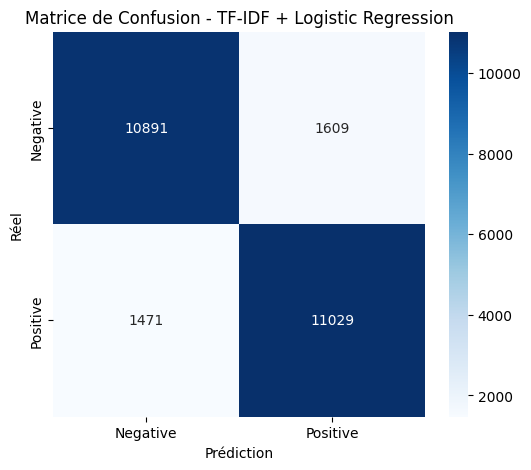

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Prédictions sur le test
y_pred = model.predict(X_test)

# Si y_test est une Series pandas d'étiquettes textuelles, on laisse comme ça.
cm = confusion_matrix(y_test, y_pred, labels=["negative", "positive"])

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
plt.title("Matrice de Confusion - TF-IDF + Logistic Regression")
plt.xlabel("Prédiction")
plt.ylabel("Réel")
plt.show()


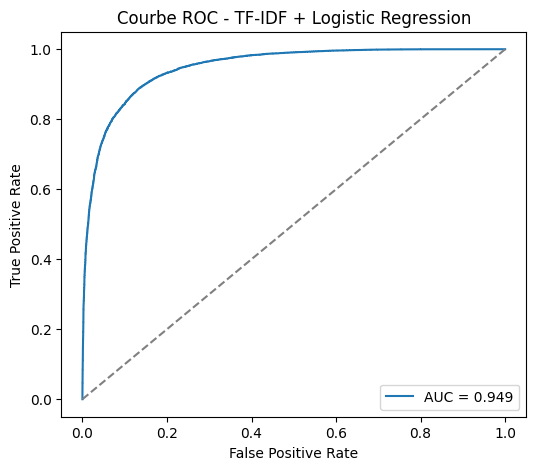

In [ ]:
from sklearn.metrics import roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt

# Obtenir un score probabiliste utilisable pour ROC
if hasattr(model, "predict_proba"):
    # Probabilité pour la classe "positive"
    y_prob = model.predict_proba(X_test)[:, 1]
elif hasattr(model, "decision_function"):
    # fallback : utiliser decision_function et min-max scaler pour avoir quelque chose entre 0 et 1
    scores = model.decision_function(X_test)
    # scaler simple en cas de besoin
    y_prob = (scores - scores.min()) / (scores.max() - scores.min())
else:
    raise AttributeError("Le modèle n'a ni predict_proba ni decision_function — impossible de tracer la ROC.")

# Préparer y_true binaire (0/1) : attention au format de y_test
# Ici on assume y_test contient des strings "positive"/"negative"
y_true = (y_test == "positive").astype(int)

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--", color="gray")
plt.title("Courbe ROC - TF-IDF + Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


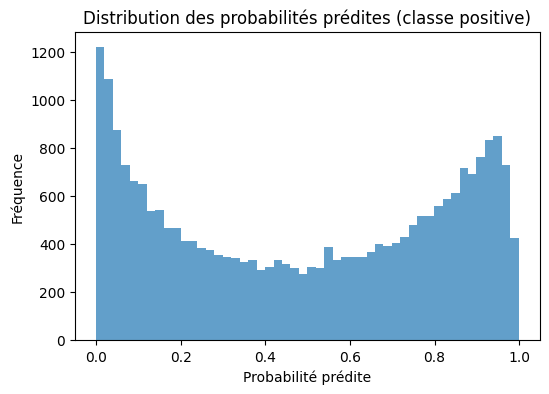

In [ ]:
import matplotlib.pyplot as plt

# y_prob doit avoir été défini dans le bloc précédent
plt.figure(figsize=(6,4))
plt.hist(y_prob, bins=50, alpha=0.7)
plt.title("Distribution des probabilités prédites (classe positive)")
plt.xlabel("Probabilité prédite")
plt.ylabel("Fréquence")
plt.show()


# BERT + Régression Logistique.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns
import matplotlib.pyplot as plt

# Entraînement du modèle
model_bert_lr = LogisticRegression(max_iter=300, solver="liblinear")
model_bert_lr.fit(X_train_distil, y_train)

LogisticRegression(max_iter=300, solver='liblinear')

In [ ]:
# Prédictions
y_pred_bert = model_bert_lr.predict(X_test_distil)

# Accuracy
acc_bert = accuracy_score(y_test, y_pred_bert)
print("Accuracy BERT + Logistic Regression :", acc_bert)

Accuracy BERT + Logistic Regression : 0.8514


In [ ]:
print(classification_report(y_test, y_pred_bert))

              precision    recall  f1-score   support

    negative       0.85      0.86      0.85     12500
    positive       0.86      0.85      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



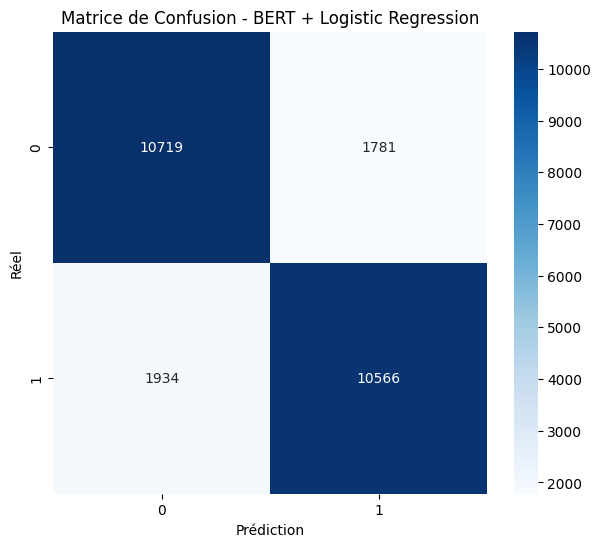

In [ ]:
cm = confusion_matrix(y_test, y_pred_bert)

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Matrice de Confusion - BERT + Logistic Regression")
plt.xlabel("Prédiction")
plt.ylabel("Réel")
plt.show()

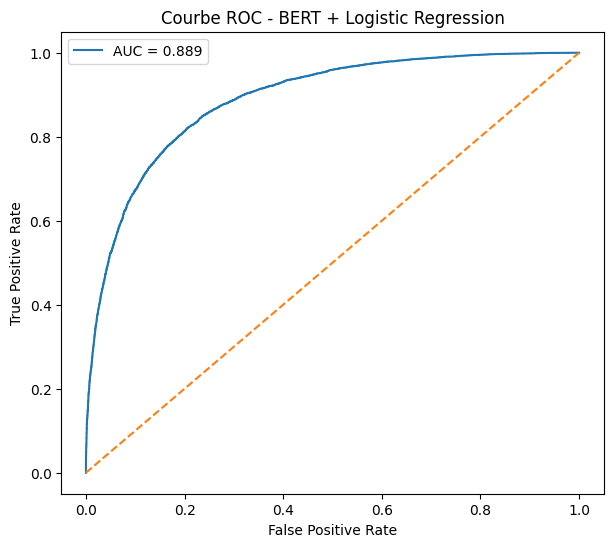

In [ ]:
# Probabilités pour la classe positive
y_prob_bert = model_bert_lr.predict_proba(X_test_bert)[:, 1]

# ROC
fpr, tpr, _ = roc_curve(y_test.map({"negative":0, "positive":1}), y_prob_bert)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.title("Courbe ROC - BERT + Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

# Régression Logistique + Word2Vec

In [ ]:
from sklearn.linear_model import LogisticRegression

# Modèle de régression logistique
logreg_w2v = LogisticRegression(max_iter=300)

# Entraînement sur les vecteurs Word2Vec
logreg_w2v.fit(X_train_w2v, y_train)

LogisticRegression(max_iter=300)

In [ ]:
y_pred_w2v = logreg_w2v.predict(X_test_w2v)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_w2v = accuracy_score(y_test, y_pred_w2v)
print("Accuracy Word2Vec + Logistic Regression :", accuracy_w2v)

print(classification_report(y_test, y_pred_w2v))

Accuracy Word2Vec + Logistic Regression : 0.85
              precision    recall  f1-score   support

    negative       0.85      0.85      0.85     12500
    positive       0.85      0.85      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



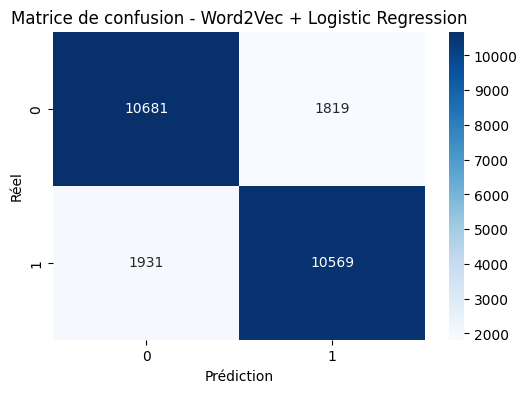

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_w2v)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Matrice de confusion - Word2Vec + Logistic Regression")
plt.xlabel("Prédiction")
plt.ylabel("Réel")
plt.show()

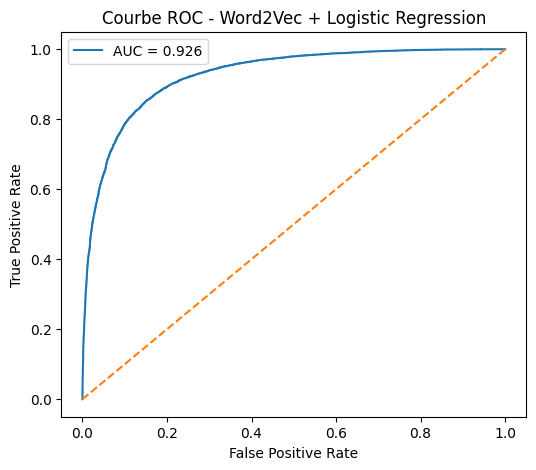

In [ ]:
from sklearn.metrics import roc_curve, auc

# Probabilité d'être "positive"
y_prob_w2v = logreg_w2v.predict_proba(X_test_w2v)[:, 1]

fpr, tpr, _ = roc_curve((y_test=="positive").astype(int), y_prob_w2v)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Courbe ROC - Word2Vec + Logistic Regression")
plt.legend()
plt.show()

#SVM + TF-IDF

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
svm_model = LinearSVC()
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

In [ ]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print("Accuracy TF-IDF + SVM:", accuracy_svm)

print(classification_report(y_test, y_pred_svm))

Accuracy TF-IDF + SVM: 0.86256
              precision    recall  f1-score   support

    negative       0.86      0.87      0.86     12500
    positive       0.87      0.85      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



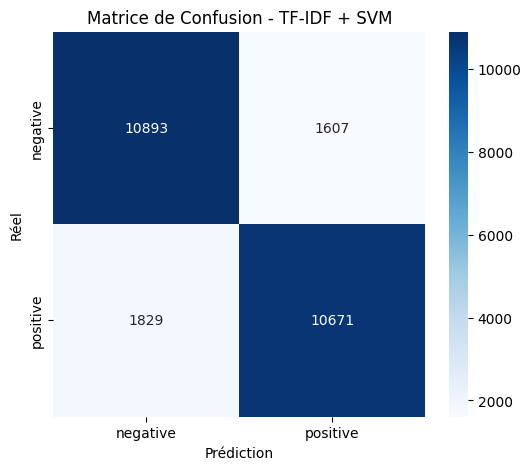

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["negative", "positive"],
            yticklabels=["negative", "positive"])
plt.title("Matrice de Confusion - TF-IDF + SVM")
plt.xlabel("Prédiction")
plt.ylabel("Réel")
plt.show()

#SVM + BERT

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_distil)
X_test_scaled = scaler.transform(X_test_distil)

In [ ]:
svm_model = LinearSVC()

svm_model.fit(X_train_scaled, y_train)

LinearSVC()

In [ ]:
y_pred_svm_bert = svm_model.predict(X_test_scaled)

print("\nAccuracy SVM + BERT embeddings :", accuracy_score(y_test, y_pred_svm_bert))

print("\nClassification Report :")
print(classification_report(y_test, y_pred_svm_bert))


Accuracy SVM + BERT embeddings : 0.85072

Classification Report :
              precision    recall  f1-score   support

    negative       0.85      0.86      0.85     12500
    positive       0.86      0.84      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



#SVM + Word2Vec

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
scaler = StandardScaler()

X_train_w2v_scaled = scaler.fit_transform(X_train_w2v)
X_test_w2v_scaled = scaler.transform(X_test_w2v)

In [ ]:
svm_model_w2v = LinearSVC()

svm_model_w2v.fit(X_train_w2v_scaled, y_train)

LinearSVC()

In [ ]:
y_pred_w2v_svm = svm_model_w2v.predict(X_test_w2v_scaled)

print("\nAccuracy SVM + Word2Vec :", accuracy_score(y_test, y_pred_w2v_svm))

print("\nClassification Report :")
print(classification_report(y_test, y_pred_w2v_svm))


Accuracy SVM + Word2Vec : 0.84944

Classification Report :
              precision    recall  f1-score   support

    negative       0.84      0.86      0.85     12500
    positive       0.85      0.84      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000

